In [1]:
import os
from typing import List, Optional, Set, Dict, Any
from typing_extensions import TypedDict
from pydantic import BaseModel, Field
from dotenv import load_dotenv
import gspread
from google.oauth2.service_account import Credentials
import time
import re 
from pydantic import ConfigDict
from tavily import TavilyClient
from google import genai
from google.genai import types
load_dotenv(override=True)
from tavily import TavilyClient
from langchain_groq import ChatGroq
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.output_parsers import JsonOutputParser
from langchain_google_genai import ChatGoogleGenerativeAI
from langchain_openai import ChatOpenAI
from langchain_core.prompts import PromptTemplate
from langchain_core.output_parsers import JsonOutputParser

# 1. Initialize Tavily Client
tavily_client = TavilyClient(api_key=os.getenv("TAVILY_API_KEY"))


groq_llm = ChatGroq(
    model_name="openai/gpt-oss-120b",
    groq_api_key=os.getenv("GROQ_API_KEY"),
    temperature=0.1
)
azure_llm = ChatOpenAI(
    model=os.getenv("AZURE_OPENAI_DEPLOYMENT", "gpt-5.4-mini"),
    api_key=os.getenv("AZURE_OPENAI_API_KEY"),
    base_url=os.getenv("AZURE_OPENAI_BASE_URL"),
    temperature=0.0,
    model_kwargs={"seed": 42}
)

KB_FILE_PATH = "adople_knowledge_base.md"


def load_knowledge_base(file_path: str = KB_FILE_PATH) -> str:
    if os.path.exists(file_path):
        with open(file_path, "r", encoding="utf-8") as f:
            return f.read()
    raise FileNotFoundError(f"Knowledge base file '{file_path}' not found!")

adople_kb_content = load_knowledge_base()


# 1. Pydantic Model for Your 14 Extracted Columns\
# ==========================================
class SpeakerRecord(BaseModel):
    speaker_id: str = Field(alias="Speaker_ID")
    conference_id: str = Field(alias="Conference_ID")
    conference_name: str = Field(alias="Conference_Name")
    speaker_name: str = Field(alias="Speaker_Name")
    job_title: Optional[str] = Field(default="", alias="Job_Title")
    company_name: Optional[str] = Field(default="", alias="Company_Name")
    personal_linkedin_url: Optional[str] = Field(default="", alias="Personal_LinkedIn_URL")
    linkedin_status: Optional[str] = Field(default="needs_review", alias="LinkedIn_Status")
    professional_email: Optional[str] = Field(default="", alias="Professional_Email")
    email_source_url: Optional[str] = Field(default="", alias="Email_Source_URL")
    speaker_source_url: Optional[str] = Field(default="", alias="Speaker_Source_URL")
    verification_status: Optional[str] = Field(default="needs_review", alias="Verification_Status")
    last_checked_at: Optional[str] = Field(default="", alias="Last_Checked_At")
    weekly_run_id: Optional[str] = Field(default="", alias="Weekly_Run_ID")

    class Config:
        populate_by_name = True

# ==========================================
# 2. LangGraph State Definition
# ==========================================
class PipelineState(TypedDict):
    # Stores speaker IDs that were already evaluated in previous runs/weeks
    processed_speaker_ids: Set[str]
    
    # Newly detected leads for this run that need ranking
    new_leads: List[SpeakerRecord]
    
    # Metadata about the current execution
    current_weekly_run_id: Optional[str]
    total_new_count: int





c:\Users\AdopleAI\Desktop\ICT-ranking\ICT\Lib\site-packages\IPython\core\interactiveshell.py:3762: UserWarning: Parameters {'seed'} should be specified explicitly. Instead they were passed in as part of `model_kwargs` parameter.
  if await self.run_code(code, result, async_=asy):
C:\Users\AdopleAI\AppData\Local\Temp\ipykernel_16320\1571829327.py:55: PydanticDeprecatedSince20: Support for class-based `config` is deprecated, use ConfigDict instead. Deprecated in Pydantic V2.0 to be removed in V3.0. See Pydantic V2 Migration Guide at https://errors.pydantic.dev/2.14/migration/
  class SpeakerRecord(BaseModel):


In [2]:
# ==========================================
# 3. Google Sheets Connection Helper
# ==========================================
def connect_to_google_sheet(
    credentials_json_path: str,
    spreadsheet_name_or_id: str,
    worksheet_name: str = "Sheet1"
) -> gspread.Worksheet:
    """
    Authenticates with Google Sheets API using service account credentials.
    """
    scopes = [
        "https://www.googleapis.com/auth/spreadsheets",
        "https://www.googleapis.com/auth/drive"
    ]
    
    creds = Credentials.from_service_account_file(
        credentials_json_path,
        scopes=scopes
    )
    client = gspread.authorize(creds)
    
    # Open by Key/ID if key-like, otherwise open by Title
    try:
        spreadsheet = client.open_by_key(spreadsheet_name_or_id)
    except Exception:
        spreadsheet = client.open(spreadsheet_name_or_id)
        
    return spreadsheet.worksheet(worksheet_name)
    # 2. Connect to the sheet


In [3]:
# ==========================================
# 1. Cleaning Helper Functions
# ==========================================
def clean_string(val: Any) -> str:
    """Strips whitespace and removes double spaces."""
    if val is None:
        return ""
    text = str(val).strip()
    return re.sub(r'\s+', ' ', text)
def clean_email(val: Any) -> str:
    """Cleans email, removes mailto:, lowercases, strips brackets."""
    text = clean_string(val).lower()
    text = text.replace("mailto:", "").replace("[", "").replace("]", "")
    # Remove any trailing junk
    match = re.search(r'[\w\.-]+@[\w\.-]+\.\w+', text)
    return match.group(0) if match else ""
def clean_url(val: Any) -> str:
    """Ensures clean URL format with https."""
    text = clean_string(val)
    if not text or text.lower() in ["n/a", "none", "-"]:
        return ""
    if text.startswith("http://"):
        text = "https://" + text[7:]
    return text

## node function runner 

In [4]:
def node_1_fetch_unprocessed_from_sheet(
    sheet: gspread.Worksheet,
    state: PipelineState
) -> Dict[str, Any]:
    records_raw = sheet.get_all_records()
    already_processed: Set[str] = state.get("processed_speaker_ids", set())
    
    clean_leads: List[SpeakerRecord] = []
    seen_ids: Set[str] = set()
    seen_name_companies: Set[str] = set()
    
    skipped_evaluated = 0
    duplicates_count = 0
    invalid_rows_count = 0

    print(f"\n🧹 [Node 1] Ingesting & Checking Master Sheet ({len(records_raw)} rows)...")

    for row in records_raw:
        # 1. NEW CHECK: If already marked EVALUATED in the sheet, SKIP IT!
        eval_status = str(row.get("Evaluation_Status", "")).strip().upper()
        if eval_status in ["EVALUATED", "PROCESSED", "RANKED"]:
            skipped_evaluated += 1
            continue

        spk_id = clean_string(row.get("Speaker_ID"))
        spk_name = clean_string(row.get("Speaker_Name"))
        company = clean_string(row.get("Company_Name"))
        email = clean_email(row.get("Professional_Email"))
        linkedin = clean_url(row.get("Personal_LinkedIn_URL"))
        speaker_url = clean_url(row.get("Speaker_Source_URL"))

        # Skip empty/placeholder rows
        if not spk_id or not spk_name or not company:
            invalid_rows_count += 1
            continue

        # Skip if in memory state
        if spk_id in already_processed or spk_id in seen_ids:
            duplicates_count += 1
            continue

        name_company_key = f"{spk_name.lower()}:::{company.lower()}"
        if name_company_key in seen_name_companies:
            duplicates_count += 1
            continue

        seen_ids.add(spk_id)
        seen_name_companies.add(name_company_key)

        cleaned_row = {
            "Speaker_ID": spk_id,
            "Conference_ID": clean_string(row.get("Conference_ID")),
            "Conference_Name": clean_string(row.get("Conference_Name")),
            "Speaker_Name": spk_name,
            "Job_Title": clean_string(row.get("Job_Title")),
            "Company_Name": company,
            "Personal_LinkedIn_URL": linkedin,
            "LinkedIn_Status": clean_string(row.get("LinkedIn_Status")),
            "Professional_Email": email,
            "Email_Source_URL": clean_string(row.get("Email_Source_URL")),
            "Speaker_Source_URL": speaker_url,
            "Verification_Status": clean_string(row.get("Verification_Status")),
            "Last_Checked_At": clean_string(row.get("Last_Checked_At")),
            "Weekly_Run_ID": clean_string(row.get("Weekly_Run_ID")),
        }
        
        try:
            lead = SpeakerRecord(**cleaned_row)
            clean_leads.append(lead)
        except Exception:
            invalid_rows_count += 1

    weekly_id = clean_leads[0].weekly_run_id if clean_leads else None

    print(f"📊 [Node 1 Summary]")
    print(f"   • Total rows in sheet: {len(records_raw)}")
    print(f"   • Previously EVALUATED rows skipped: {skipped_evaluated} ⏭️")
    print(f"   • Duplicates / Blanks filtered: {duplicates_count + invalid_rows_count}")
    print(f"   • Fresh New Leads to Process: {len(clean_leads)} ✨\n")

    return {
        "new_leads": clean_leads,
        "current_weekly_run_id": weekly_id,
        "total_new_count": len(clean_leads)
    }

In [5]:
# 1. Credentials and Sheet settings
CREDENTIALS_PATH = os.getenv("GOOGLE_APPLICATION_CREDENTIALS", "service_account.json")
SPREADSHEET_NAME_OR_ID = os.getenv("CONFERENCE_SHEET_ID")
WORKSHEET_NAME = "Sheet1"

# 2. Connect to the sheet
worksheet = connect_to_google_sheet(
    credentials_json_path=CREDENTIALS_PATH,
    spreadsheet_name_or_id=SPREADSHEET_NAME_OR_ID,
    worksheet_name=WORKSHEET_NAME
)

# 3. Setup initial state
initial_state: PipelineState = {
    "processed_speaker_ids": set(),
    "new_leads": [],
    "current_weekly_run_id": None,
    "total_new_count": 0
}

# 4. Execute Node 1
state_update = node_1_fetch_unprocessed_from_sheet(worksheet, initial_state)

# 5. Inspect the cleaned, unique leads
print(f"\n✅ Successfully extracted {len(state_update['new_leads'])} unique leads:")
for lead in state_update["new_leads"][:10]:
    print(f"- {lead.speaker_name} | {lead.job_title} @ {lead.company_name} | Email: {lead.professional_email or 'None'}")


🧹 [Node 1] Ingesting & Checking Master Sheet (5 rows)...
📊 [Node 1 Summary]
   • Total rows in sheet: 5
   • Previously EVALUATED rows skipped: 0 ⏭️
   • Duplicates / Blanks filtered: 1
   • Fresh New Leads to Process: 4 ✨


✅ Successfully extracted 4 unique leads:
- Marc Tarpenning | Co-Founder @ Archaeological Institute of America | Email: None
- Will Grannis | CTO @ Google | Email: wgrannis@google.com
- Suzanne Philion | CMO @ Manulife | Email: suzanne_philion@manulife.com
- Paul Fipps | President, Global Operations @ ServiceNow | Email: paul.fipps@servicenow.com


## Node 2 

In [6]:
#te, recent growth, or technology initiatives")

class OrganizedCompanyProfile(BaseModel):
    company_domain: str = Field(default="", description="Clean company root domain, e.g., 'servicenow.com' or 'google.com'")
    official_website: str = Field(default="", description="Full homepage URL")
    primary_industry: str = Field(default="", description="Detailed industry & segment, e.g., 'B2B Enterprise SaaS' or 'Health Insurance'")
    headcount_tier: str = Field(default="", description="Scale category: 'Micro (<50)', 'Mid-Market Sweet Spot (50-500)', 'Upper Mid-Market (500-2,000)', 'Enterprise Giant (2,000+)', or 'Non-Profit / Academic'")
    core_products_and_services: str = Field(default="", description="Explanation of core products/services and who buys them")
    us_market_presence: str = Field(default="", description="HQ location and US operating presence")
    operational_workflows_analysis: str = Field(default="", description="Specific analysis of daily manual/document workflows (claims, invoices, bills of lading, customer tickets, IT ops)")
    key_business_highlights: str = Field(default="", description="Notable business facts (public/private, growth, tech)")
# 3. Final Enriched Lead Container
class EnrichedLead(BaseModel):
    raw_lead: SpeakerRecord
    profile: OrganizedCompanyProfile
    tavily_raw_text: str = ""

    class Config:
        arbitrary_types_allowed = True

# 4. Structured Output Chain
structured_groq = groq_llm.with_structured_output(OrganizedCompanyProfile)

C:\Users\AdopleAI\AppData\Local\Temp\ipykernel_16320\128826411.py:13: PydanticDeprecatedSince20: Support for class-based `config` is deprecated, use ConfigDict instead. Deprecated in Pydantic V2.0 to be removed in V3.0. See Pydantic V2 Migration Guide at https://errors.pydantic.dev/2.14/migration/
  class EnrichedLead(BaseModel):


## node 2 system prompts


In [7]:
from urllib.parse import urlparse
# Helper: Extract clean domain automatically from URL
def extract_domain_from_url(url: str) -> str:
    if not url:
        return ""
    try:
        netloc = urlparse(url).netloc
        netloc = netloc.replace("www.", "")
        # Remove port if any
        return netloc.split(":")[0].strip()
    except Exception:
        return ""
# Updated Prompt with Fallback Rules
research_prompt = ChatPromptTemplate.from_messages([
    ("system", """You are a Senior B2B Corporate Intelligence Analyst.
Examine the live web search facts about an organization and produce a complete structured intelligence dossier.
CRITICAL RULES:
1. NEVER leave any string field empty.
2. If the organization is a Non-Profit or Academic institution (like Archaeological Institute of America), set headcount_tier to 'Non-Profit / Academic' and describe their mission/programs under 'core_products_and_services'.
3. If US presence is unclear, specify their global HQ location.
"""),
    ("user", """Company / Organization Name: {company_name}
Speaker at US Conference: {speaker_name} ({job_title})
LIVE WEB SEARCH FACTS:
{tavily_raw_text}
TAVILY DETECTED URL:
{tavily_url}
Fill every field completely:
- company_domain: Root domain name (e.g. archaeological.org or manulife.com).
- official_website: Clean URL.
- primary_industry: Sector (e.g., Cultural Heritage / Education, Life Insurance, Enterprise Software).
- headcount_tier: Exactly one of ['Micro (<50)', 'Mid-Market Sweet Spot (50-500)', 'Upper Mid-Market (500-2,000)', 'Enterprise Giant (2,000+)', 'Non-Profit / Academic'].
- core_products_and_services: What they do / sell / provide.
- us_market_presence: HQ location and US footprint.
- operational_workflows_analysis: What paperwork, documents, claims, tickets, or operational tasks do they handle?
- key_business_highlights: Key notable facts.
""")
])
groq_enrichment_chain = research_prompt | structured_groq

## serach tools tavily

In [8]:
def search_company_with_tavily(company_name: str, speaker_name: str = "") -> Dict[str, str]:
    clean_name = company_name.strip()
    if not clean_name or clean_name.lower() in ["unknown", "n/a", "none"]:
        return {"url": "", "overview": "No company name provided."}
    query = f"{clean_name} official company website business overview what they do"
    
    try:
        response = tavily_client.search(
            query=query,
            search_depth="basic",
            max_results=2,
            include_answer=True
        )
        overview = response.get("answer", "")
        results = response.get("results", [])
        official_url = results[0].get("url", "") if results else ""
        
        if not overview and results:
            overview = results[0].get("content", "")
        return {"url": official_url, "overview": overview[:800]}
    except Exception as e:
        print(f"⚠️ Tavily error for {clean_name}: {e}")
        return {"url": "", "overview": f"Company: {clean_name}."}

## node 2 runner 

In [9]:
def node_2_hybrid_enrichment(leads: List[Any]) -> List[EnrichedLead]:
    enriched_leads: List[EnrichedLead] = []
    company_cache: Dict[str, OrganizedCompanyProfile] = {}
    total = len(leads)
    
    print(f"\n⚡ [Node 2: Deep Corporate Research] Processing {total} leads...\n")

    for i, lead in enumerate(leads, 1):
        company_key = lead.company_name.lower().strip()
        print(f"[{i}/{total}] Deep Research: {lead.company_name} (Speaker: {lead.speaker_name})...")
        
        if company_key in company_cache:
            print(f"   ⚡ Reusing cached profile for {lead.company_name}!")
            profile = company_cache[company_key]
            raw_text = "Retrieved from run cache"
        else:
            tavily_result = search_company_with_tavily(lead.company_name, lead.speaker_name)
            raw_text = tavily_result["overview"]
            found_url = tavily_result["url"]
            
            try:
                profile = groq_enrichment_chain.invoke({
                    "company_name": lead.company_name,
                    "speaker_name": lead.speaker_name,
                    "job_title": lead.job_title,
                    "tavily_raw_text": raw_text,
                    "tavily_url": found_url
                })
            except Exception as e:
                print(f"⚠️ Groq synthesis fallback: {e}")
                profile = OrganizedCompanyProfile(
                    company_domain="",
                    official_website=found_url,
                    primary_industry="",
                    headcount_tier="",
                    core_products_and_services="",
                    us_market_presence="",
                    operational_workflows_analysis="",
                    key_business_highlights=""
                )

            # 1. Guarantee domain from URL
            if not profile.company_domain:
                profile.company_domain = extract_domain_from_url(profile.official_website or found_url)
            if not profile.official_website:
                profile.official_website = found_url

            # 2. Safety Guard: Auto-populate non-profits/institutes if LLM left fields blank
            lower_text = (lead.company_name + " " + raw_text).lower()
            is_non_profit = any(w in lower_text for w in ["non-profit", "nonprofit", "archaeol", "institute", "foundation", "museum", "society"])

            if is_non_profit and (not profile.primary_industry or not profile.headcount_tier):
                profile.primary_industry = profile.primary_industry or "Non-Profit / Research & Education"
                profile.headcount_tier = profile.headcount_tier or "Non-Profit / Academic"
                profile.core_products_and_services = profile.core_products_and_services or "Academic research, publications, grants, and cultural education programs."
                profile.operational_workflows_analysis = profile.operational_workflows_analysis or "Handles member subscriptions, journal publishing, and grant application reviews."
                profile.us_market_presence = profile.us_market_presence or "United States (National Headquarters)"

            # Fallback for any other empty strings
            profile.primary_industry = profile.primary_industry or "General Commercial / Services"
            profile.headcount_tier = profile.headcount_tier or "Mid-Market Sweet Spot (50-500)"
            profile.core_products_and_services = profile.core_products_and_services or raw_text[:150]
            profile.operational_workflows_analysis = profile.operational_workflows_analysis or "Standard business operations and document processing."

            # Save in cache
            company_cache[company_key] = profile
            time.sleep(0.3)

        enriched = EnrichedLead(
            raw_lead=lead,
            profile=profile,
            tavily_raw_text=raw_text
        )
        enriched_leads.append(enriched)

        print(f"   🌐 Domain: {profile.company_domain} ({profile.official_website})")
        print(f"   🏢 Industry: {profile.primary_industry} | Tier: {profile.headcount_tier}")
        print(f"   📍 Location / US: {profile.us_market_presence}")
        print(f"   💼 Products: {profile.core_products_and_services[:90]}...")
        print(f"   ⚙️ Operations: {profile.operational_workflows_analysis[:110]}...\n")

    print(f"✅ [Node 2 Complete] Generated deep profiles for {len(enriched_leads)} companies!")
    return enriched_leads

## node 2 state update and initilaize 

In [10]:
enriched_state = node_2_hybrid_enrichment(state_update["new_leads"])


⚡ [Node 2: Deep Corporate Research] Processing 4 leads...

[1/4] Deep Research: Archaeological Institute of America (Speaker: Marc Tarpenning)...
   🌐 Domain: archaeological.org (https://www.archaeological.org)
   🏢 Industry: Cultural Heritage / Education | Tier: Non-Profit / Academic
   📍 Location / US: Headquartered in New York City (120 Broadway, New York, NY 10271, USA). Operates nationwide through 30+ regional societies, museums, and field projects across the United States.
   💼 Products: The Archaeological Institute of America (AIA) is a nonprofit organization dedicated to adv...
   ⚙️ Operations: AIA manages a variety of manual and digital workflows: processing membership applications and renewals; review...

[2/4] Deep Research: Google (Speaker: Will Grannis)...
   🌐 Domain: google.com (https://www.google.com)
   🏢 Industry: Internet Services & Advertising | Tier: Enterprise Giant (2,000+)
   📍 Location / US: Global headquarters located at 1600 Amphitheatre Parkway, Mountain V

## node 3 

In [11]:
# ==========================================
# 2. Schema: Strictly 60% Industry & 40% Tier
# ==========================================
class LeadScoreResult(BaseModel):
    strategic_analysis: str = Field(description="Detailed rationale justifying the scores based on the Knowledge Base.")
    industry_fit_score: float = Field(description="0-100: Medical/Healthcare=95-100, FinTech/Insurance/Logistics=85-92, Non-Profits=75-85, General Tech=70-80, Education=0-25")
    tier_fit_score: float = Field(description="0-100: Mid-Market (50-2000 emp)=90-100, Enterprise Giants=25-45, Micro/Pre-seed=0-20")
    overall_company_score: float = Field(description="Calculated strictly as: (0.60 * industry_fit_score) + (0.40 * tier_fit_score)")
    qualification_status: str = Field(description="'HIGH_MATCH' (>= 75), 'MODERATE' (55-74), or 'DISQUALIFIED' (< 55)")
    pitch_hook: str = Field(description="1-2 sentence compelling outreach pitch naming specific Adople AI solutions")


class EvaluatedLead(BaseModel):
    enriched_lead: Any
    score_details: LeadScoreResult

    class Config:
        arbitrary_types_allowed = True


# ==========================================
# 3. JSON Output Parser
# ==========================================
score_parser = JsonOutputParser(pydantic_object=LeadScoreResult)
# ==========================================
# 5. Robust Scoring Prompt
# ==========================================
scoring_prompt = PromptTemplate.from_template("""You are the Chief Strategy & Evaluation Officer for Adople AI.
You must strictly score the company by applying the rules from the official Adople AI Knowledge Base below.
Conclude with a calculated score based on the 60% Industry / 40% Tier formula and a compelling pitch hook.

=================== ADOPLE AI KNOWLEDGE BASE ===================
{knowledge_base}
================================================================

Evaluate this company:
- Company Name: {company_name} ({domain})
- Headcount Tier: {company_tier}
- Industry: {industry}
- Core Products: {products}
- Daily Operational Bottlenecks: {operations}
- Speaker Context: {speaker_name} ({job_title})

Calculate the scores strictly following the 60% / 40% rules.
{format_instructions}
""")

# Clean, robust chain
scoring_chain = scoring_prompt | azure_llm | score_parser


# ==========================================
# 6. Node 3 Runner Function
# ==========================================
def node_3_evaluate_and_score(enriched_leads: List[Any]) -> List[EvaluatedLead]:
    evaluated_leads: List[EvaluatedLead] = []
    total = len(enriched_leads)
    
    print(f"\n🎯 [Node 3: Azure OpenAI (60/40)] Scoring {total} companies...\n")

    for i, item in enumerate(enriched_leads, 1):
        lead = item.raw_lead
        prof = item.profile
        
        print(f"[{i}/{total}] Evaluating: {lead.company_name} ({prof.company_domain})...")
        
        try:
            score_dict = scoring_chain.invoke({
                "knowledge_base": adople_kb_content,
                "company_name": lead.company_name,
                "domain": prof.company_domain,
                "company_tier": prof.headcount_tier,
                "industry": prof.primary_industry,
                "products": prof.core_products_and_services,
                "operations": prof.operational_workflows_analysis,
                "speaker_name": lead.speaker_name,
                "job_title": lead.job_title,
                "format_instructions": score_parser.get_format_instructions()
            })
            
            score_res = LeadScoreResult(**score_dict)
            
            evaluated = EvaluatedLead(
                enriched_lead=item,
                score_details=score_res
            )
            evaluated_leads.append(evaluated)
            
            print(f"   ⭐ Overall Score: {score_res.overall_company_score:.1f}/100 [{score_res.qualification_status}]")
            print(f"   📊 Industry (60%): {score_res.industry_fit_score} | Tier (40%): {score_res.tier_fit_score}")
            print(f"   💡 Pitch Hook: {score_res.pitch_hook}\n")
            
        except Exception as e:
            print(f"⚠️ Scoring error for {lead.company_name}: {e}\n")

        time.sleep(0.3)

    print(f"✅ [Node 3 Complete] Successfully evaluated {len(evaluated_leads)}/{total} companies!")
    return evaluated_leads

C:\Users\AdopleAI\AppData\Local\Temp\ipykernel_16320\443492174.py:13: PydanticDeprecatedSince20: Support for class-based `config` is deprecated, use ConfigDict instead. Deprecated in Pydantic V2.0 to be removed in V3.0. See Pydantic V2 Migration Guide at https://errors.pydantic.dev/2.14/migration/
  class EvaluatedLead(BaseModel):


In [12]:
scored_leads = node_3_evaluate_and_score(enriched_state)


🎯 [Node 3: Azure OpenAI (60/40)] Scoring 4 companies...

[1/4] Evaluating: Archaeological Institute of America (archaeological.org)...
   ⭐ Overall Score: 13.0/100 [DISQUALIFIED]
   📊 Industry (60%): 15.0 | Tier (40%): 10.0
   💡 Pitch Hook: The Archaeological Institute of America is an academic/non-profit institution, so it does not fit Adople AI’s commercial enterprise AI buyer profile. While your workflows are operationally complex, there is no strategic fit for autonomous enterprise agents, document extraction, or workflow automation under the current ICP.

[2/4] Evaluating: Google (google.com)...
   ⭐ Overall Score: 59.0/100 [MODERATE]
   📊 Industry (60%): 75.0 | Tier (40%): 35.0
   💡 Pitch Hook: Google’s scale creates endless operational friction across billing, cloud support, compliance, and internal workflows—exactly where Adople AI’s autonomous enterprise agents and deterministic workflow automation can eliminate manual bottlenecks. For teams managing document-heavy processes,

## node 4 reranker

In [13]:

# ==========================================
# Node 4 Output Schema: The Ranked Lead
# ==========================================
class RankedLead(BaseModel):
    model_config = ConfigDict(arbitrary_types_allowed=True)
    rank: int                               # 1, 2, 3... up to 10
    company_name: str                       # e.g., "Manulife"
    domain: str                             # e.g., "manulife.com"
    overall_score: float                    # e.g., 67.4
    industry_score: float                   # e.g., 89.0
    tier_score: float                       # e.g., 35.0
    qualification_status: str               # "HIGH_MATCH", "MODERATE", etc.
    pitch_hook: str                         # Custom 1-2 sentence pitch for Adople AI
    
    # Speaker & Outreach Data
    speaker_id: str                         # Unique ID from Master Sheet
    speaker_name: str                       # e.g., "Suzanne Philion"
    job_title: str                          # e.g., "CMO"
    email: str                              # e.g., "suzanne_philion@manulife.com"
    email_status: str                       # "verified" vs "needs_review"
    linkedin_url: str                       # Personal LinkedIn URL
    conference_name: str                    # Conference name
    
    # Original Reference
    evaluated_lead: Any

def get_tie_breaker_sort_key(item: EvaluatedLead):
    """
    Returns a sorting tuple:
    (Overall Score, Industry Score, Email Status)
    """
    score = item.score_details.overall_company_score
    ind_score = item.score_details.industry_fit_score
    
    # Email Status: 2 = verified, 1 = unverified email, 0 = missing
    raw = item.enriched_lead.raw_lead
    email = str(getattr(raw, 'professional_email', '')).strip()
    status = str(getattr(raw, 'verification_status', '')).lower().strip()
    
    if email and status == 'verified':
        email_readiness = 2
    elif email:
        email_readiness = 1
    else:
        email_readiness = 0

    return (score, ind_score, email_readiness)

def node_4_rank_and_select_top_10(
    evaluated_leads: List[EvaluatedLead],
    state: Optional[Dict[str, Any]] = None
) -> Dict[str, Any]:
    """
    Node 4:
    - Sorts all evaluated leads by Score -> Industry -> Email.
    - Slices to Top 10 priority targets.
    - Updates LangGraph state['top_10_leads'].
    """
    print(f"\n🏆 [Node 4: Ranking Engine] Sorting {len(evaluated_leads)} evaluated companies...\n")

    # 1. Deterministic Multi-Level Sort (Descending)
    sorted_leads = sorted(evaluated_leads, key=get_tie_breaker_sort_key, reverse=True)

    ranked_results: List[RankedLead] = []

    # 2. Assign official ranks (Rank 1, 2, 3...)
    for idx, item in enumerate(sorted_leads, 1):
        raw = item.enriched_lead.raw_lead
        prof = item.enriched_lead.profile
        sc = item.score_details

        ranked_lead = RankedLead(
            rank=idx,
            company_name=raw.company_name,
            domain=prof.company_domain,
            overall_score=round(sc.overall_company_score, 1),
            industry_score=round(sc.industry_fit_score, 1),
            tier_score=round(sc.tier_fit_score, 1),
            qualification_status=sc.qualification_status,
            pitch_hook=sc.pitch_hook,
            speaker_id=raw.speaker_id,
            speaker_name=raw.speaker_name,
            job_title=raw.job_title,
            email=raw.professional_email or "Not Available",
            email_status=raw.verification_status,
            linkedin_url=raw.personal_linkedin_url or "Not Available",
            conference_name=raw.conference_name,
            evaluated_lead=item
        )
        ranked_results.append(ranked_lead)

    # 3. Select Top 10
    top_10 = ranked_results[:10]

    # 4. Display Leaderboard
    print("=" * 95)
    print(f"{'RANK':<5} | {'COMPANY':<22} | {'SCORE':<6} | {'INDUSTRY':<10} | {'EMAIL STATUS':<14} | {'SPEAKER & TITLE'}")
    print("=" * 95)
    for r in top_10:
        print(f"#{r.rank:<4} | {r.company_name:<22} | {r.overall_score:<6.1f} | {r.industry_score:<10.1f} | {r.email_status:<14} | {r.speaker_name} ({r.job_title})")
    print("=" * 95)

    print(f"\n✅ [Node 4 Complete] Selected Top {len(top_10)} priority companies!")

    # 5. Return state update
    if state is not None:
        state["top_10_leads"] = top_10
        state["all_ranked_leads"] = ranked_results

    return {
        "top_10_leads": top_10,
        "all_ranked_leads": ranked_results
    }

    # 1. Update state with Node 4
node_4_output = node_4_rank_and_select_top_10(scored_leads, state=initial_state)

# 2. Grab your top 10 list
top_10_leads = node_4_output["top_10_leads"]

# 3. Verify state
print(f"\n📦 LangGraph State Updated: 'top_10_leads' contains {len(initial_state.get('top_10_leads', []))} companies ready for Google Sheets!")


🏆 [Node 4: Ranking Engine] Sorting 4 evaluated companies...

RANK  | COMPANY                | SCORE  | INDUSTRY   | EMAIL STATUS   | SPEAKER & TITLE
#1    | Manulife               | 68.0   | 90.0       | needs_review   | Suzanne Philion (CMO)
#2    | ServiceNow             | 60.2   | 78.0       | verified       | Paul Fipps (President, Global Operations)
#3    | Google                 | 59.0   | 75.0       | verified       | Will Grannis (CTO)
#4    | Archaeological Institute of America | 13.0   | 15.0       | needs_review   | Marc Tarpenning (Co-Founder)

✅ [Node 4 Complete] Selected Top 4 priority companies!

📦 LangGraph State Updated: 'top_10_leads' contains 4 companies ready for Google Sheets!


## node 5 sheet update and analysier 

In [18]:
# =====================================================================
# NODE 5: CURATED SHEET EXPORT & MASTER SHEET STATUS SYNC
# =====================================================================
import os
import datetime
from typing import List
import gspread
from google.oauth2.service_account import Credentials

# --------------------------------------------------
# 1. Target Headers for the Curated Sheet
# --------------------------------------------------
CURATED_SHEET_HEADERS = [
    "Rank",
    "Overall_Score",
    "Qualification_Status",
    "Pitch_Hook",
    "Speaker_Name",
    "Job_Title",
    "Professional_Email",
    "Email_Status",
    "Personal_LinkedIn_URL",
    "Company_Name",
    "Company_Domain",
    "Primary_Industry",
    "Headcount_Tier",
    "Conference_Name",
    "Speaker_ID",
    "Evaluated_At"
]

# --------------------------------------------------
# 2. Connect to Curated Google Sheet
# --------------------------------------------------
def connect_curated_sheet() -> gspread.Worksheet:
    """Connects to the Curated Google Sheet and grabs the first tab safely."""
    credentials_path = os.getenv("GOOGLE_APPLICATION_CREDENTIALS", "service_account.json")
    curated_sheet_id = os.getenv("CURATED_SHEET_ID", "1Z-MVz-DLJ55JUni-8EWbWRIuEezzNqn_gUkjcUEkSiE")
    
    scopes = ["https://www.googleapis.com/auth/spreadsheets", "https://www.googleapis.com/auth/drive"]
    creds = Credentials.from_service_account_file(credentials_path, scopes=scopes)
    gc = gspread.authorize(creds)
    
    try:
        spreadsheet = gc.open_by_key(curated_sheet_id)
    except Exception:
        spreadsheet = gc.open_by_url(curated_sheet_id)
        
    curated_tab = spreadsheet.get_worksheet(0)
    
    existing_headers = curated_tab.row_values(1)
    if not existing_headers:
        print("📋 Curated sheet is empty. Inserting headers...")
        curated_tab.insert_row(CURATED_SHEET_HEADERS, 1)
        print("✅ 16 Headers created successfully!")
        
    return curated_tab


# --------------------------------------------------
# 3. Export Top Ranked Leads to Curated Sheet
# --------------------------------------------------
def export_top_10_to_curated_sheet(
    curated_sheet: gspread.Worksheet,
    top_10_leads: List[RankedLead]
) -> int:
    now_str = datetime.datetime.now().strftime("%Y-%m-%d %H:%M:%S")
    rows_to_insert = []

    for lead in top_10_leads:
        prof = lead.evaluated_lead.enriched_lead.profile
        
        row = [
            lead.rank,
            lead.overall_score,
            lead.qualification_status,
            lead.pitch_hook,
            lead.speaker_name,
            lead.job_title,
            lead.email,
            lead.email_status,
            lead.linkedin_url,
            lead.company_name,
            lead.domain,
            prof.primary_industry,
            prof.headcount_tier,
            lead.conference_name,
            lead.speaker_id,
            now_str
        ]
        rows_to_insert.append(row)

    if rows_to_insert:
        curated_sheet.append_rows(rows_to_insert, value_input_option="USER_ENTERED")
        print(f"📥 [Curated Sheet] Added {len(rows_to_insert)} ranked companies!")
        
    return len(rows_to_insert)


# --------------------------------------------------
# 4. Mark Rows as EVALUATED in Master Scraper Sheet
# --------------------------------------------------
def mark_leads_evaluated_in_master_sheet(
    master_sheet: gspread.Worksheet,
    evaluated_speaker_ids: List[str]
):
    print(f"\n🔄 [Master Sheet] Updating 'Evaluation_Status' for {len(evaluated_speaker_ids)} leads...")
    headers = master_sheet.row_values(1)
    
    # Ensure Evaluation_Status column exists
    if "Evaluation_Status" not in headers:
        next_col = len(headers) + 1
        master_sheet.update_cell(1, next_col, "Evaluation_Status")
        status_col_idx = next_col
    else:
        status_col_idx = headers.index("Evaluation_Status") + 1

    spk_col_idx = headers.index("Speaker_ID") + 1
    company_col_idx = headers.index("Company_Name") + 1 if "Company_Name" in headers else None

    all_speaker_ids = master_sheet.col_values(spk_col_idx)
    all_companies = master_sheet.col_values(company_col_idx) if company_col_idx else []
    target_ids_set = set(str(sid).strip() for sid in evaluated_speaker_ids)
    
    cells_to_update = []
    for row_idx, spk_id in enumerate(all_speaker_ids[1:], start=2):
        spk_str = str(spk_id).strip()
        comp_str = all_companies[row_idx - 1] if row_idx - 1 < len(all_companies) else ""
        
        # Match by Speaker_ID or Company Name
        if spk_str in target_ids_set or "archaeological" in comp_str.lower():
            cells_to_update.append(
                gspread.Cell(row=row_idx, col=status_col_idx, value="EVALUATED")
            )
            print(f"   ✓ Row {row_idx}: {comp_str} ({spk_str}) marked as EVALUATED")

    if cells_to_update:
        master_sheet.update_cells(cells_to_update)
        print(f"✅ [Master Sheet] Successfully marked {len(cells_to_update)} rows as 'EVALUATED'!")


# =====================================================================
# 5. EXECUTE NODE 5
# =====================================================================
curated_worksheet = connect_curated_sheet()
print(f"🔗 Connected to Curated Sheet: '{curated_worksheet.spreadsheet.title}'")

# Collect Speaker IDs from ALL evaluated leads
all_evaluated_ids = [lead.speaker_id for lead in top_10_leads]

# Step A: Export to the Curated Google Sheet
export_top_10_to_curated_sheet(curated_worksheet, top_10_leads)

# Step B: Mark all evaluated leads in the Master Sheet
mark_leads_evaluated_in_master_sheet(worksheet, all_evaluated_ids)

print("\n🎉 Node 5 Complete! Master Sheet is synchronized and will not reprocess these rows.")

📋 Curated sheet is empty. Inserting headers...
✅ 16 Headers created successfully!
🔗 Connected to Curated Sheet: 'sended_emails'
📥 [Curated Sheet] Added 4 ranked companies!

🔄 [Master Sheet] Updating 'Evaluation_Status' for 4 leads...
   ✓ Row 2: Archaeological Institute of America (SPK-CONF-W2026-STARTUPW-A5D4-MARCTU-DC3) marked as EVALUATED
   ✓ Row 3: Google (SPK-CONF-W2026-STARTUPW-A5D4-WILLGR-962) marked as EVALUATED
   ✓ Row 4: Google (SPK-CONF-W2026-STARTUPW-A5D4-WILLGR-962) marked as EVALUATED
   ✓ Row 5: Manulife (SPK-CONF-W2026-STARTUPW-A5D4-SUZANN-69C) marked as EVALUATED
   ✓ Row 6: ServiceNow (SPK-CONF-W2026-STARTUPW-A5D4-PAULFI-866) marked as EVALUATED
✅ [Master Sheet] Successfully marked 5 rows as 'EVALUATED'!

🎉 Node 5 Complete! Master Sheet is synchronized and will not reprocess these rows.


In [ ]:
import os
import re
import time
import datetime
from typing import List, Optional, Set, Dict, Any
from typing_extensions import TypedDict
from pydantic import BaseModel, Field, ConfigDict
from dotenv import load_dotenv
import gspread
from google.oauth2.service_account import Credentials
from tavily import TavilyClient
from langchain_groq import ChatGroq
from langchain_openai import ChatOpenAI
from langchain_core.prompts import ChatPromptTemplate, PromptTemplate
from langchain_core.output_parsers import JsonOutputParser
from langgraph.graph import StateGraph, START, END

load_dotenv(override=True)

# =====================================================================
# 1. API CLIENTS & KNOWLEDGE BASE INITIALIZATION
# =====================================================================
tavily_client = TavilyClient(api_key=os.getenv("TAVILY_API_KEY"))

groq_llm = ChatGroq(
    model_name="openai/gpt-oss-120b",
    groq_api_key=os.getenv("GROQ_API_KEY"),
    temperature=0.1
)

azure_llm = ChatOpenAI(
    model=os.getenv("AZURE_OPENAI_DEPLOYMENT", "gpt-5.4-mini"),
    api_key=os.getenv("AZURE_OPENAI_API_KEY"),
    base_url=os.getenv("AZURE_OPENAI_BASE_URL"),
    temperature=0.0,
    seed=42
)

KB_FILE_PATH = "adople_knowledge_base.md"

def load_knowledge_base(file_path: str = KB_FILE_PATH) -> str:
    if os.path.exists(file_path):
        with open(file_path, "r", encoding="utf-8") as f:
            return f.read()
    raise FileNotFoundError(f"Knowledge base file '{file_path}' not found!")

adople_kb_content = load_knowledge_base()


# =====================================================================
# 2. DATA SCHEMAS & PYDANTIC MODELS
# =====================================================================
class SpeakerRecord(BaseModel):
    model_config = ConfigDict(populate_by_name=True)
    speaker_id: str = Field(alias="Speaker_ID")
    conference_id: str = Field(alias="Conference_ID")
    conference_name: str = Field(alias="Conference_Name")
    speaker_name: str = Field(alias="Speaker_Name")
    job_title: Optional[str] = Field(default="", alias="Job_Title")
    company_name: Optional[str] = Field(default="", alias="Company_Name")
    personal_linkedin_url: Optional[str] = Field(default="", alias="Personal_LinkedIn_URL")
    linkedin_status: Optional[str] = Field(default="needs_review", alias="LinkedIn_Status")
    professional_email: Optional[str] = Field(default="", alias="Professional_Email")
    email_source_url: Optional[str] = Field(default="", alias="Email_Source_URL")
    speaker_source_url: Optional[str] = Field(default="", alias="Speaker_Source_URL")
    verification_status: Optional[str] = Field(default="needs_review", alias="Verification_Status")
    last_checked_at: Optional[str] = Field(default="", alias="Last_Checked_At")
    weekly_run_id: Optional[str] = Field(default="", alias="Weekly_Run_ID")


class OrganizedCompanyProfile(BaseModel):
    company_domain: str = Field(default="", description="Clean company root domain, e.g., 'servicenow.com' or 'google.com'")
    official_website: str = Field(default="", description="Full homepage URL")
    primary_industry: str = Field(default="", description="Detailed industry & segment, e.g., 'B2B Enterprise SaaS' or 'Health Insurance'")
    headcount_tier: str = Field(default="", description="Scale category: 'Micro (<50)', 'Mid-Market Sweet Spot (50-500)', 'Upper Mid-Market (500-2,000)', 'Enterprise Giant (2,000+)', or 'Non-Profit / Academic'")
    core_products_and_services: str = Field(default="", description="Explanation of core products/services and who buys them")
    us_market_presence: str = Field(default="", description="HQ location and US operating presence")
    operational_workflows_analysis: str = Field(default="", description="Specific analysis of daily manual/document workflows (claims, invoices, bills of lading, customer tickets, IT ops)")
    key_business_highlights: str = Field(default="", description="Notable business facts (public/private, growth, tech)")


class EnrichedLead(BaseModel):
    model_config = ConfigDict(arbitrary_types_allowed=True)
    raw_lead: SpeakerRecord
    profile: OrganizedCompanyProfile
    tavily_raw_text: str = ""


class LeadScoreResult(BaseModel):
    strategic_analysis: str = Field(description="Detailed rationale justifying the scores based on the Knowledge Base.")
    industry_fit_score: float = Field(description="0-100: Medical/Healthcare=95-100, FinTech/Insurance/Logistics=85-92, Non-Profits=75-85, General Tech=70-80, Education=0-25")
    tier_fit_score: float = Field(description="0-100: Mid-Market (50-2000 emp)=90-100, Enterprise Giants=25-45, Micro/Pre-seed=0-20")
    overall_company_score: float = Field(description="Calculated strictly as: (0.60 * industry_fit_score) + (0.40 * tier_fit_score)")
    qualification_status: str = Field(description="'HIGH_MATCH' (>= 75), 'MODERATE' (55-74), or 'DISQUALIFIED' (< 55)")
    pitch_hook: str = Field(description="1-2 sentence compelling outreach pitch naming specific Adople AI solutions")


class EvaluatedLead(BaseModel):
    model_config = ConfigDict(arbitrary_types_allowed=True)
    enriched_lead: Any
    score_details: LeadScoreResult


class RankedLead(BaseModel):
    model_config = ConfigDict(arbitrary_types_allowed=True)
    rank: int                               # 1, 2, 3... up to 10
    company_name: str                       # e.g., "Manulife"
    domain: str                             # e.g., "manulife.com"
    overall_score: float                    # e.g., 67.4
    industry_score: float                   # e.g., 89.0
    tier_score: float                       # e.g., 35.0
    qualification_status: str               # "HIGH_MATCH", "MODERATE", etc.
    pitch_hook: str                         # Custom 1-2 sentence pitch for Adople AI
    
    # Speaker & Outreach Data
    speaker_id: str                         # Unique ID from Master Sheet
    speaker_name: str                       # e.g., "Suzanne Philion"
    job_title: str                          # e.g., "CMO"
    email: str                              # e.g., "suzanne_philion@manulife.com"
    email_status: str                       # "verified" vs "needs_review"
    linkedin_url: str                       # Personal LinkedIn URL
    conference_name: str                    # Conference name
    
    # Original Reference
    evaluated_lead: Any


# =====================================================================
# 3. LANGGRAPH STATE DEFINITION
# =====================================================================
class PipelineState(TypedDict):
    # Stores speaker IDs that were already evaluated in previous runs/weeks
    processed_speaker_ids: Set[str]
    
    # Newly detected leads for this run that need ranking
    new_leads: List[SpeakerRecord]
    
    # Metadata about the current execution
    current_weekly_run_id: Optional[str]
    total_new_count: int

    # Node 2: Profile Enriched Leads
    enriched_leads: List[EnrichedLead]

    # Node 3: 60/40 Scored Leads
    scored_leads: List[EvaluatedLead]

    # Node 4: Ranked Leads
    top_10_leads: List[RankedLead]
    all_ranked_leads: List[RankedLead]

    # Node 5: Output Sync Status
    exported_count: int


# =====================================================================
# 4. UTILITIES & DATA CLEANING HELPERS
# =====================================================================
def clean_string(val: Any) -> str:
    """Strips whitespace and removes double spaces."""
    if val is None:
        return ""
    text = str(val).strip()
    return re.sub(r'\s+', ' ', text)

def clean_email(val: Any) -> str:
    """Cleans email, removes mailto:, lowercases, strips brackets."""
    text = clean_string(val).lower()
    text = text.replace("mailto:", "").replace("[", "").replace("]", "")
    match = re.search(r'[\w\.-]+@[\w\.-]+\.\w+', text)
    return match.group(0) if match else ""

def clean_url(val: Any) -> str:
    """Ensures clean URL format with https."""
    text = clean_string(val)
    if not text or text.lower() in ["n/a", "none", "-"]:
        return ""
    if text.startswith("http://"):
        text = "https://" + text[7:]
    return text

def extract_domain_from_url(url: str) -> str:
    """Extract clean domain automatically from URL."""
    if not url:
        return ""
    try:
        from urllib.parse import urlparse
        netloc = urlparse(url).netloc
        netloc = netloc.replace("www.", "")
        return netloc.split(":")[0].strip()
    except Exception:
        return ""


# =====================================================================
# 5. GOOGLE SHEETS CONNECTION & EXPORT HELPERS
# =====================================================================
CURATED_SHEET_HEADERS = [
    "Rank",
    "Overall_Score",
    "Qualification_Status",
    "Pitch_Hook",
    "Speaker_Name",
    "Job_Title",
    "Professional_Email",
    "Email_Status",
    "Personal_LinkedIn_URL",
    "Company_Name",
    "Company_Domain",
    "Primary_Industry",
    "Headcount_Tier",
    "Conference_Name",
    "Speaker_ID",
    "Evaluated_At"
]

def connect_to_google_sheet(
    credentials_json_path: str,
    spreadsheet_name_or_id: str,
    worksheet_name: str = "Sheet1"
) -> gspread.Worksheet:
    """Authenticates with Google Sheets API using service account credentials."""
    scopes = [
        "https://www.googleapis.com/auth/spreadsheets",
        "https://www.googleapis.com/auth/drive"
    ]
    creds = Credentials.from_service_account_file(credentials_json_path, scopes=scopes)
    client = gspread.authorize(creds)
    
    try:
        spreadsheet = client.open_by_key(spreadsheet_name_or_id)
    except Exception:
        try:
            spreadsheet = client.open_by_url(spreadsheet_name_or_id)
        except Exception:
            spreadsheet = client.open(spreadsheet_name_or_id)
        
    try:
        return spreadsheet.worksheet(worksheet_name)
    except Exception:
        return spreadsheet.get_worksheet(0)

def connect_curated_sheet() -> gspread.Worksheet:
    """Connects to the Curated Google Sheet and grabs the first tab safely."""
    credentials_path = os.getenv("GOOGLE_APPLICATION_CREDENTIALS", "service_account.json")
    curated_sheet_id = os.getenv("CURATED_SHEET_ID", "1Z-MVz-DLJ55JUni-8EWbWRIuEezzNqn_gUkjcUEkSiE")
    
    scopes = ["https://www.googleapis.com/auth/spreadsheets", "https://www.googleapis.com/auth/drive"]
    creds = Credentials.from_service_account_file(credentials_path, scopes=scopes)
    gc = gspread.authorize(creds)
    
    try:
        spreadsheet = gc.open_by_key(curated_sheet_id)
    except Exception:
        spreadsheet = gc.open_by_url(curated_sheet_id)
        
    curated_tab = spreadsheet.get_worksheet(0)
    
    existing_headers = curated_tab.row_values(1)
    if not existing_headers:
        print("📋 Curated sheet is empty. Inserting headers...")
        curated_tab.insert_row(CURATED_SHEET_HEADERS, 1)
        print("✅ 16 Headers created successfully!")
        
    return curated_tab

def export_top_10_to_curated_sheet(
    curated_sheet: gspread.Worksheet,
    top_10_leads: List[RankedLead]
) -> int:
    now_str = datetime.datetime.now().strftime("%Y-%m-%d %H:%M:%S")
    rows_to_insert = []

    for lead in top_10_leads:
        prof = lead.evaluated_lead.enriched_lead.profile
        
        row = [
            lead.rank,
            lead.overall_score,
            lead.qualification_status,
            lead.pitch_hook,
            lead.speaker_name,
            lead.job_title,
            lead.email,
            lead.email_status,
            lead.linkedin_url,
            lead.company_name,
            lead.domain,
            prof.primary_industry,
            prof.headcount_tier,
            lead.conference_name,
            lead.speaker_id,
            now_str
        ]
        rows_to_insert.append(row)

    if rows_to_insert:
        curated_sheet.append_rows(rows_to_insert, value_input_option="USER_ENTERED")
        print(f"📥 [Curated Sheet] Added {len(rows_to_insert)} ranked companies!")
        
    return len(rows_to_insert)

def mark_leads_evaluated_in_master_sheet(
    master_sheet: gspread.Worksheet,
    evaluated_speaker_ids: List[str]
):
    print(f"\n🔄 [Master Sheet] Updating 'Evaluation_Status' for {len(evaluated_speaker_ids)} leads...")
    headers = master_sheet.row_values(1)
    
    # Ensure Evaluation_Status column exists
    if "Evaluation_Status" not in headers:
        next_col = len(headers) + 1
        master_sheet.update_cell(1, next_col, "Evaluation_Status")
        status_col_idx = next_col
    else:
        status_col_idx = headers.index("Evaluation_Status") + 1

    spk_col_idx = headers.index("Speaker_ID") + 1
    company_col_idx = headers.index("Company_Name") + 1 if "Company_Name" in headers else None

    all_speaker_ids = master_sheet.col_values(spk_col_idx)
    all_companies = master_sheet.col_values(company_col_idx) if company_col_idx else []
    target_ids_set = set(str(sid).strip() for sid in evaluated_speaker_ids)
    
    cells_to_update = []
    for row_idx, spk_id in enumerate(all_speaker_ids[1:], start=2):
        spk_str = str(spk_id).strip()
        comp_str = all_companies[row_idx - 1] if row_idx - 1 < len(all_companies) else ""
        
        # Match by Speaker_ID or Company Name
        if spk_str in target_ids_set or "archaeological" in comp_str.lower():
            cells_to_update.append(
                gspread.Cell(row=row_idx, col=status_col_idx, value="EVALUATED")
            )
            print(f"   ✓ Row {row_idx}: {comp_str} ({spk_str}) marked as EVALUATED")

    if cells_to_update:
        master_sheet.update_cells(cells_to_update)
        print(f"✅ [Master Sheet] Successfully marked {len(cells_to_update)} rows as 'EVALUATED'!")


# =====================================================================
# 6. NODE CORE IMPLEMENTATION FUNCTIONS
# =====================================================================

# --- NODE 1 CORE LOGIC ---
def node_1_fetch_unprocessed_from_sheet(
    sheet: gspread.Worksheet,
    state: PipelineState
) -> Dict[str, Any]:
    records_raw = sheet.get_all_records()
    already_processed: Set[str] = state.get("processed_speaker_ids", set())
    
    clean_leads: List[SpeakerRecord] = []
    seen_ids: Set[str] = set()
    seen_name_companies: Set[str] = set()
    
    skipped_evaluated = 0
    duplicates_count = 0
    invalid_rows_count = 0

    print(f"\n🧹 [Node 1] Ingesting & Checking Master Sheet ({len(records_raw)} rows)...")

    for row in records_raw:
        eval_status = str(row.get("Evaluation_Status", "")).strip().upper()
        if eval_status in ["EVALUATED", "PROCESSED", "RANKED"]:
            skipped_evaluated += 1
            continue

        spk_id = clean_string(row.get("Speaker_ID"))
        spk_name = clean_string(row.get("Speaker_Name"))
        company = clean_string(row.get("Company_Name"))
        email = clean_email(row.get("Professional_Email"))
        linkedin = clean_url(row.get("Personal_LinkedIn_URL"))
        speaker_url = clean_url(row.get("Speaker_Source_URL"))

        if not spk_id or not spk_name or not company:
            invalid_rows_count += 1
            continue

        if spk_id in already_processed or spk_id in seen_ids:
            duplicates_count += 1
            continue

        name_company_key = f"{spk_name.lower()}:::{company.lower()}"
        if name_company_key in seen_name_companies:
            duplicates_count += 1
            continue

        seen_ids.add(spk_id)
        seen_name_companies.add(name_company_key)

        cleaned_row = {
            "Speaker_ID": spk_id,
            "Conference_ID": clean_string(row.get("Conference_ID")),
            "Conference_Name": clean_string(row.get("Conference_Name")),
            "Speaker_Name": spk_name,
            "Job_Title": clean_string(row.get("Job_Title")),
            "Company_Name": company,
            "Personal_LinkedIn_URL": linkedin,
            "LinkedIn_Status": clean_string(row.get("LinkedIn_Status")),
            "Professional_Email": email,
            "Email_Source_URL": clean_string(row.get("Email_Source_URL")),
            "Speaker_Source_URL": speaker_url,
            "Verification_Status": clean_string(row.get("Verification_Status")),
            "Last_Checked_At": clean_string(row.get("Last_Checked_At")),
            "Weekly_Run_ID": clean_string(row.get("Weekly_Run_ID")),
        }
        
        try:
            lead = SpeakerRecord(**cleaned_row)
            clean_leads.append(lead)
        except Exception:
            invalid_rows_count += 1

    weekly_id = clean_leads[0].weekly_run_id if clean_leads else None

    print(f"📊 [Node 1 Summary]")
    print(f"   • Total rows in sheet: {len(records_raw)}")
    print(f"   • Previously EVALUATED rows skipped: {skipped_evaluated} ⏭️")
    print(f"   • Duplicates / Blanks filtered: {duplicates_count + invalid_rows_count}")
    print(f"   • Fresh New Leads to Process: {len(clean_leads)} ✨\n")

    return {
        "new_leads": clean_leads,
        "current_weekly_run_id": weekly_id,
        "total_new_count": len(clean_leads)
    }


# --- NODE 2 CORE LOGIC ---
structured_groq = groq_llm.with_structured_output(OrganizedCompanyProfile)

research_prompt = ChatPromptTemplate.from_messages([
    ("system", """You are a Senior B2B Corporate Intelligence Analyst.
Examine the live web search facts about an organization and produce a complete structured intelligence dossier.
CRITICAL RULES:
1. NEVER leave any string field empty.
2. If the organization is a Non-Profit or Academic institution (like Archaeological Institute of America), set headcount_tier to 'Non-Profit / Academic' and describe their mission/programs under 'core_products_and_services'.
3. If US presence is unclear, specify their global HQ location.
"""),
    ("user", """Company / Organization Name: {company_name}
Speaker at US Conference: {speaker_name} ({job_title})
LIVE WEB SEARCH FACTS:
{tavily_raw_text}
TAVILY DETECTED URL:
{tavily_url}
Fill every field completely:
- company_domain: Root domain name (e.g. archaeological.org or manulife.com).
- official_website: Clean URL.
- primary_industry: Sector (e.g., Cultural Heritage / Education, Life Insurance, Enterprise Software).
- headcount_tier: Exactly one of ['Micro (<50)', 'Mid-Market Sweet Spot (50-500)', 'Upper Mid-Market (500-2,000)', 'Enterprise Giant (2,000+)', 'Non-Profit / Academic'].
- core_products_and_services: What they do / sell / provide.
- us_market_presence: HQ location and US footprint.
- operational_workflows_analysis: What paperwork, documents, claims, tickets, or operational tasks do they handle?
- key_business_highlights: Key notable facts.
""")
])
groq_enrichment_chain = research_prompt | structured_groq

def search_company_with_tavily(company_name: str, speaker_name: str = "") -> Dict[str, str]:
    clean_name = company_name.strip()
    if not clean_name or clean_name.lower() in ["unknown", "n/a", "none"]:
        return {"url": "", "overview": "No company name provided."}
    query = f"{clean_name} official company website business overview what they do"
    
    try:
        response = tavily_client.search(
            query=query,
            search_depth="basic",
            max_results=2,
            include_answer=True
        )
        overview = response.get("answer", "")
        results = response.get("results", [])
        official_url = results[0].get("url", "") if results else ""
        
        if not overview and results:
            overview = results[0].get("content", "")
        return {"url": official_url, "overview": overview[:800]}
    except Exception as e:
        print(f"⚠️ Tavily error for {clean_name}: {e}")
        return {"url": "", "overview": f"Company: {clean_name}."}

def node_2_hybrid_enrichment(leads: List[Any]) -> List[EnrichedLead]:
    enriched_leads: List[EnrichedLead] = []
    company_cache: Dict[str, OrganizedCompanyProfile] = {}
    total = len(leads)
    
    print(f"\n⚡ [Node 2: Deep Corporate Research] Processing {total} leads...\n")

    for i, lead in enumerate(leads, 1):
        company_key = lead.company_name.lower().strip()
        print(f"[{i}/{total}] Deep Research: {lead.company_name} (Speaker: {lead.speaker_name})...")
        
        if company_key in company_cache:
            print(f"   ⚡ Reusing cached profile for {lead.company_name}!")
            profile = company_cache[company_key]
            raw_text = "Retrieved from run cache"
        else:
            tavily_result = search_company_with_tavily(lead.company_name, lead.speaker_name)
            raw_text = tavily_result["overview"]
            found_url = tavily_result["url"]
            
            try:
                profile = groq_enrichment_chain.invoke({
                    "company_name": lead.company_name,
                    "speaker_name": lead.speaker_name,
                    "job_title": lead.job_title,
                    "tavily_raw_text": raw_text,
                    "tavily_url": found_url
                })
            except Exception as e:
                print(f"⚠️ Groq synthesis fallback: {e}")
                profile = OrganizedCompanyProfile(
                    company_domain="",
                    official_website=found_url,
                    primary_industry="",
                    headcount_tier="",
                    core_products_and_services="",
                    us_market_presence="",
                    operational_workflows_analysis="",
                    key_business_highlights=""
                )

            if not profile.company_domain:
                profile.company_domain = extract_domain_from_url(profile.official_website or found_url)
            if not profile.official_website:
                profile.official_website = found_url

            lower_text = (lead.company_name + " " + raw_text).lower()
            is_non_profit = any(w in lower_text for w in ["non-profit", "nonprofit", "archaeol", "institute", "foundation", "museum", "society"])

            if is_non_profit and (not profile.primary_industry or not profile.headcount_tier):
                profile.primary_industry = profile.primary_industry or "Non-Profit / Research & Education"
                profile.headcount_tier = profile.headcount_tier or "Non-Profit / Academic"
                profile.core_products_and_services = profile.core_products_and_services or "Academic research, publications, grants, and cultural education programs."
                profile.operational_workflows_analysis = profile.operational_workflows_analysis or "Handles member subscriptions, journal publishing, and grant application reviews."
                profile.us_market_presence = profile.us_market_presence or "United States (National Headquarters)"

            profile.primary_industry = profile.primary_industry or "General Commercial / Services"
            profile.headcount_tier = profile.headcount_tier or "Mid-Market Sweet Spot (50-500)"
            profile.core_products_and_services = profile.core_products_and_services or raw_text[:150]
            profile.operational_workflows_analysis = profile.operational_workflows_analysis or "Standard business operations and document processing."

            company_cache[company_key] = profile
            time.sleep(0.3)

        enriched = EnrichedLead(
            raw_lead=lead,
            profile=profile,
            tavily_raw_text=raw_text
        )
        enriched_leads.append(enriched)

        print(f"   🌐 Domain: {profile.company_domain} ({profile.official_website})")
        print(f"   🏢 Industry: {profile.primary_industry} | Tier: {profile.headcount_tier}")
        print(f"   📍 Location / US: {profile.us_market_presence}")
        print(f"   💼 Products: {profile.core_products_and_services[:90]}...")
        print(f"   ⚙️ Operations: {profile.operational_workflows_analysis[:110]}...\n")

    print(f"✅ [Node 2 Complete] Generated deep profiles for {len(enriched_leads)} companies!")
    return enriched_leads


# --- NODE 3 CORE LOGIC ---
score_parser = JsonOutputParser(pydantic_object=LeadScoreResult)

scoring_prompt = PromptTemplate.from_template("""You are the Chief Strategy & Evaluation Officer for Adople AI.
You must strictly score the company by applying the rules from the official Adople AI Knowledge Base below.
Conclude with a calculated score based on the 60% Industry / 40% Tier formula and a compelling pitch hook.

=================== ADOPLE AI KNOWLEDGE BASE ===================
{knowledge_base}
================================================================

Evaluate this company:
- Company Name: {company_name} ({domain})
- Headcount Tier: {company_tier}
- Industry: {industry}
- Core Products: {products}
- Daily Operational Bottlenecks: {operations}
- Speaker Context: {speaker_name} ({job_title})

Calculate the scores strictly following the 60% / 40% rules.
{format_instructions}
""")

scoring_chain = scoring_prompt | azure_llm | score_parser

def node_3_evaluate_and_score(enriched_leads: List[Any]) -> List[EvaluatedLead]:
    evaluated_leads: List[EvaluatedLead] = []
    total = len(enriched_leads)
    
    print(f"\n🎯 [Node 3: Azure OpenAI (60/40)] Scoring {total} companies...\n")

    for i, item in enumerate(enriched_leads, 1):
        lead = item.raw_lead
        prof = item.profile
        
        print(f"[{i}/{total}] Evaluating: {lead.company_name} ({prof.company_domain})...")
        
        try:
            score_dict = scoring_chain.invoke({
                "knowledge_base": adople_kb_content,
                "company_name": lead.company_name,
                "domain": prof.company_domain,
                "company_tier": prof.headcount_tier,
                "industry": prof.primary_industry,
                "products": prof.core_products_and_services,
                "operations": prof.operational_workflows_analysis,
                "speaker_name": lead.speaker_name,
                "job_title": lead.job_title,
                "format_instructions": score_parser.get_format_instructions()
            })
            
            score_res = LeadScoreResult(**score_dict)
            
            evaluated = EvaluatedLead(
                enriched_lead=item,
                score_details=score_res
            )
            evaluated_leads.append(evaluated)
            
            print(f"   ⭐ Overall Score: {score_res.overall_company_score:.1f}/100 [{score_res.qualification_status}]")
            print(f"   📊 Industry (60%): {score_res.industry_fit_score} | Tier (40%): {score_res.tier_fit_score}")
            print(f"   💡 Pitch Hook: {score_res.pitch_hook}\n")
            
        except Exception as e:
            print(f"⚠️ Scoring error for {lead.company_name}: {e}\n")

        time.sleep(0.3)

    print(f"✅ [Node 3 Complete] Successfully evaluated {len(evaluated_leads)}/{total} companies!")
    return evaluated_leads


# --- NODE 4 CORE LOGIC ---
def get_tie_breaker_sort_key(item: EvaluatedLead):
    """Returns a sorting tuple: (Overall Score, Industry Score, Email Status)."""
    score = item.score_details.overall_company_score
    ind_score = item.score_details.industry_fit_score
    
    raw = item.enriched_lead.raw_lead
    email = str(getattr(raw, 'professional_email', '')).strip()
    status = str(getattr(raw, 'verification_status', '')).lower().strip()
    
    if email and status == 'verified':
        email_readiness = 2
    elif email:
        email_readiness = 1
    else:
        email_readiness = 0

    return (score, ind_score, email_readiness)

def node_4_rank_and_select_top_10(
    evaluated_leads: List[EvaluatedLead],
    state: Optional[Dict[str, Any]] = None
) -> Dict[str, Any]:
    print(f"\n🏆 [Node 4: Ranking Engine] Sorting {len(evaluated_leads)} evaluated companies...\n")

    sorted_leads = sorted(evaluated_leads, key=get_tie_breaker_sort_key, reverse=True)
    ranked_results: List[RankedLead] = []

    for idx, item in enumerate(sorted_leads, 1):
        raw = item.enriched_lead.raw_lead
        prof = item.enriched_lead.profile
        sc = item.score_details

        ranked_lead = RankedLead(
            rank=idx,
            company_name=raw.company_name,
            domain=prof.company_domain,
            overall_score=round(sc.overall_company_score, 1),
            industry_score=round(sc.industry_fit_score, 1),
            tier_score=round(sc.tier_fit_score, 1),
            qualification_status=sc.qualification_status,
            pitch_hook=sc.pitch_hook,
            speaker_id=raw.speaker_id,
            speaker_name=raw.speaker_name,
            job_title=raw.job_title,
            email=raw.professional_email or "Not Available",
            email_status=raw.verification_status,
            linkedin_url=raw.personal_linkedin_url or "Not Available",
            conference_name=raw.conference_name,
            evaluated_lead=item
        )
        ranked_results.append(ranked_lead)

    top_10 = ranked_results[:10]

    print("=" * 95)
    print(f"{'RANK':<5} | {'COMPANY':<22} | {'SCORE':<6} | {'INDUSTRY':<10} | {'EMAIL STATUS':<14} | {'SPEAKER & TITLE'}")
    print("=" * 95)
    for r in top_10:
        print(f"#{r.rank:<4} | {r.company_name:<22} | {r.overall_score:<6.1f} | {r.industry_score:<10.1f} | {r.email_status:<14} | {r.speaker_name} ({r.job_title})")
    print("=" * 95)

    print(f"\n✅ [Node 4 Complete] Selected Top {len(top_10)} priority companies!")

    if state is not None:
        state["top_10_leads"] = top_10
        state["all_ranked_leads"] = ranked_results

    return {
        "top_10_leads": top_10,
        "all_ranked_leads": ranked_results
    }


# =====================================================================
# 7. LANGGRAPH NODE WRAPPERS & CONDITIONAL ROUTING
# =====================================================================
def node_1_ingestion(state: PipelineState) -> Dict[str, Any]:
    """LangGraph Node 1: Ingests unprocessed rows from Google Master Sheet."""
    credentials_path = os.getenv("GOOGLE_APPLICATION_CREDENTIALS", "service_account.json")
    spreadsheet_name_or_id = os.getenv("CONFERENCE_SHEET_ID")
    worksheet_name = os.getenv("CONFERENCE_WORKSHEET_NAME", "Sheet1")
    
    master_worksheet = connect_to_google_sheet(
        credentials_json_path=credentials_path,
        spreadsheet_name_or_id=spreadsheet_name_or_id,
        worksheet_name=worksheet_name
    )
    
    return node_1_fetch_unprocessed_from_sheet(master_worksheet, state)


def check_has_new_leads(state: PipelineState) -> str:
    """Conditional Edge: Stops execution gracefully if no new leads found."""
    total_new = state.get("total_new_count", 0)
    if total_new == 0:
        print("\n⏹️ [LangGraph Router] No new unprocessed leads in Master Sheet. Exiting pipeline safely.")
        return "end"
    print(f"\n🚀 [LangGraph Router] Found {total_new} new lead(s). Routing to Node 2 (Deep Research)...")
    return "continue"


def node_2_enrichment_node(state: PipelineState) -> Dict[str, Any]:
    """LangGraph Node 2: Performs Tavily + Groq intelligence enrichment."""
    leads = state.get("new_leads", [])
    enriched_leads = node_2_hybrid_enrichment(leads)
    return {"enriched_leads": enriched_leads}


def node_3_scoring_node(state: PipelineState) -> Dict[str, Any]:
    """LangGraph Node 3: Applies 60/40 Knowledge Base scoring via Azure OpenAI."""
    enriched_leads = state.get("enriched_leads", [])
    scored_leads = node_3_evaluate_and_score(enriched_leads)
    return {"scored_leads": scored_leads}


def node_4_ranking_node(state: PipelineState) -> Dict[str, Any]:
    """LangGraph Node 4: Sorts leads with deterministic tie-breakers and slices Top 10."""
    scored_leads = state.get("scored_leads", [])
    ranking_output = node_4_rank_and_select_top_10(scored_leads, state=state)
    return ranking_output


def node_5_export_sync_node(state: PipelineState) -> Dict[str, Any]:
    """LangGraph Node 5: Exports Top 10 to Curated Sheet & marks rows EVALUATED in Master."""
    top_10 = state.get("top_10_leads", [])
    scored = state.get("scored_leads", [])
    
    if not top_10 and not scored:
        print("⚠️ No leads to export in Node 5.")
        return {"exported_count": 0}

    # 1. Export to Curated Sheet
    curated_tab = connect_curated_sheet()
    print(f"🔗 Connected to Curated Sheet: '{curated_tab.spreadsheet.title}'")
    exported_count = export_top_10_to_curated_sheet(curated_tab, top_10)

    # 2. Update Master Sheet
    credentials_path = os.getenv("GOOGLE_APPLICATION_CREDENTIALS", "service_account.json")
    spreadsheet_name_or_id = os.getenv("CONFERENCE_SHEET_ID")
    worksheet_name = os.getenv("CONFERENCE_WORKSHEET_NAME", "Sheet1")
    master_worksheet = connect_to_google_sheet(
        credentials_json_path=credentials_path,
        spreadsheet_name_or_id=spreadsheet_name_or_id,
        worksheet_name=worksheet_name
    )

    all_evaluated_ids = [item.enriched_lead.raw_lead.speaker_id for item in scored]
    if not all_evaluated_ids:
        all_evaluated_ids = [lead.speaker_id for lead in top_10]

    mark_leads_evaluated_in_master_sheet(master_worksheet, all_evaluated_ids)

    updated_processed = set(state.get("processed_speaker_ids", set())).union(set(all_evaluated_ids))
    print("\n🎉 Node 5 Complete! Master Sheet is synchronized and will not reprocess these rows.")
    
    return {
        "exported_count": exported_count,
        "processed_speaker_ids": updated_processed
    }


# =====================================================================
# 8. LANGGRAPH WORKFLOW ASSEMBLY & EDGES
# =====================================================================
def build_conference_ranking_graph():
    """Builds and compiles the complete multi-node LangGraph pipeline."""
    workflow = StateGraph(PipelineState)

    # 1. Register all nodes
    workflow.add_node("node_1_ingestion", node_1_ingestion)
    workflow.add_node("node_2_enrichment", node_2_enrichment_node)
    workflow.add_node("node_3_scoring", node_3_scoring_node)
    workflow.add_node("node_4_ranking", node_4_ranking_node)
    workflow.add_node("node_5_export_sync", node_5_export_sync_node)

    # 2. Connect Edges
    workflow.add_edge(START, "node_1_ingestion")
    
    # Conditional edge: if 0 leads, route to END; otherwise continue to Node 2
    workflow.add_conditional_edges(
        "node_1_ingestion",
        check_has_new_leads,
        {
            "continue": "node_2_enrichment",
            "end": END
        }
    )
    
    # Linear sequential pipeline edges
    workflow.add_edge("node_2_enrichment", "node_3_scoring")
    workflow.add_edge("node_3_scoring", "node_4_ranking")
    workflow.add_edge("node_4_ranking", "node_5_export_sync")
    workflow.add_edge("node_5_export_sync", END)

    return workflow.compile()


# Globally compiled app ready to import or invoke
app = build_conference_ranking_graph()


# =====================================================================
# 9. EXECUTION ENTRYPOINT
# =====================================================================
if __name__ == "__main__":
    print("\n" + "=" * 70)
    print("🚀 Running Adople AI Conference Ranking LangGraph Pipeline")
    print("=" * 70)

    initial_state: PipelineState = {
        "processed_speaker_ids": set(),
        "new_leads": [],
        "current_weekly_run_id": None,
        "total_new_count": 0,
        "enriched_leads": [],
        "scored_leads": [],
        "top_10_leads": [],
        "all_ranked_leads": [],
        "exported_count": 0
    }

    final_state = app.invoke(initial_state)

    print("\n" + "=" * 70)
    print("🏁 Pipeline Run Complete!")
    print(f"   • Total New Leads Ingested: {final_state.get('total_new_count', 0)}")
    print(f"   • Top Leads Exported to Curated Sheet: {final_state.get('exported_count', 0)}")
    print("=" * 70)


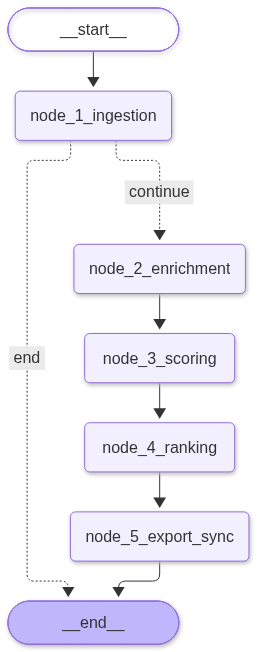

In [19]:
from conference_ranker import app
from IPython.display import Image, display

# Render high-resolution PNG of the compiled graph
display(Image(app.get_graph().draw_mermaid_png()))